# SmartBlood — Week 3: Forecasting with XGBoost

This notebook uses the feature-engineered dataset created in `02_Feature_Engineering_SmartBlood.ipynb`.

Pipeline:

**Feature-engineered dataset → time-based split → baselines → Random Forest → XGBoost → evaluation → final model → saved predictions/model**

The target is `target_demand`, which represents **next-day demand for the same blood group and component**.

> No random shuffling is used because this is a time-series forecasting problem.


## 1. Import libraries

If XGBoost is not installed, run `pip install xgboost` once in a separate cell or terminal. Do not reinstall it every time the notebook runs.


In [1]:
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
from xgboost import XGBRegressor

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:.3f}")


## 2. Load the feature-engineered dataset

This file is produced by the previous notebook.


In [2]:
DATA_PATH = "../data/features/blood_demand_features.csv"

df = pd.read_csv(DATA_PATH)

df["date"] = pd.to_datetime(df["date"], errors="coerce")

print("Dataset shape:", df.shape)
print("Date range:", df["date"].min(), "→", df["date"].max())

df.head()


Dataset shape: (16800, 35)
Date range: 2023-01-31 00:00:00 → 2024-12-30 00:00:00


,date,blood_group,component,demand,collected,issued,opening_stock,closing_stock,expired,emergency,day_of_week,day_of_week_num,month,month_name,year,quarter,is_weekend,blood_product,calculated_closing_stock,stock_difference,expiry_rate,shortage_risk,stock_coverage_ratio,excess_stock_risk,expiry_risk,emergency_risk,demand_lag_1,demand_lag_7,demand_rolling_7,demand_lag_14,demand_lag_30,demand_rolling_14,demand_rolling_30,emergency_requests_lag_1,target_demand
0,2023-01-31,A+,Plasma,29,32,25,145,152,0,2,Tuesday,1,1,January,2023,1,0,A+ - Plasma,152,0,0.000,0,5.067,1,0,1,23.000,28.000,30.000,41.000,32.000,28.429,30.800,3.000,30.000
1,2023-02-01,A+,Plasma,30,24,29,152,147,0,3,Wednesday,2,2,February,2023,1,0,A+ - Plasma,147,0,0.000,0,4.742,1,0,1,29.000,30.000,30.143,26.000,35.000,27.571,30.700,2.000,25.000
2,2023-02-02,A+,Plasma,25,18,25,147,140,0,1,Thursday,3,2,February,2023,1,0,A+ - Plasma,140,0,0.000,0,5.385,1,0,1,30.000,32.000,30.143,25.000,23.000,27.857,30.533,3.000,26.000
3,2023-02-03,A+,Plasma,26,25,25,140,140,0,1,Friday,4,2,February,2023,1,0,A+ - Plasma,140,0,0.000,0,5.185,1,0,1,25.000,28.000,29.143,21.000,52.000,27.857,30.600,1.000,21.000
4,2023-02-04,A+,Plasma,21,27,21,140,145,1,1,Saturday,5,2,February,2023,1,1,A+ - Plasma,145,0,0.006,0,6.591,1,1,1,26.000,32.000,28.857,26.000,32.000,28.214,29.733,1.000,25.000


## 3. Basic checks and sorting

The data must be ordered by blood group, component, and date because the lag/rolling features are group-specific.


In [3]:
print("Missing values before cleaning:")
print(df.isna().sum())

df = df.sort_values(
    ["blood_group", "component", "date"]
).reset_index(drop=True)

print("\nBlood groups:", sorted(df["blood_group"].dropna().unique()))
print("Components:", sorted(df["component"].dropna().unique()))


Missing values before cleaning:
date                        0
blood_group                 0
component                   0
demand                      0
collected                   0
issued                      0
opening_stock               0
closing_stock               0
expired                     0
emergency                   0
day_of_week                 0
day_of_week_num             0
month                       0
month_name                  0
year                        0
quarter                     0
is_weekend                  0
blood_product               0
calculated_closing_stock    0
stock_difference            0
expiry_rate                 0
shortage_risk               0
stock_coverage_ratio        0
excess_stock_risk           0
expiry_risk                 0
emergency_risk              0
demand_lag_1                0
demand_lag_7                0
demand_rolling_7            0
demand_lag_14               0
demand_lag_30               0
demand_rolling_14           0
demand_r

## 4. Create calendar features for the forecasted day

`target_demand` is tomorrow's demand. Therefore, calendar variables such as weekday/weekend should describe **tomorrow**, not today.

The existing lag and rolling features remain unchanged because they are calculated from information available before the prediction.


In [4]:
df["target_date"] = df["date"] + pd.Timedelta(days=1)

df["target_day_of_week_num"] = df["target_date"].dt.dayofweek
df["target_month"] = df["target_date"].dt.month
df["target_quarter"] = df["target_date"].dt.quarter
df["target_is_weekend"] = (df["target_day_of_week_num"] >= 5).astype(int)

df[[
    "date",
    "target_date",
    "demand",
    "target_demand",
    "target_day_of_week_num",
    "target_month",
    "target_quarter",
    "target_is_weekend"
]].head()


,date,target_date,demand,target_demand,target_day_of_week_num,target_month,target_quarter,target_is_weekend
0,2023-01-31,2023-02-01,29,30.000,2,2,1,0
1,2023-02-01,2023-02-02,30,25.000,3,2,1,0
2,2023-02-02,2023-02-03,25,26.000,4,2,1,0
3,2023-02-03,2023-02-04,26,21.000,5,2,1,1
4,2023-02-04,2023-02-05,21,25.000,6,2,1,1


## 5. Select forecasting features

The model predicts `target_demand`.

Blood group and component are one-hot encoded so the pooled model knows which blood product it is forecasting.


In [5]:
numeric_features = [
    "demand",
    "demand_lag_1",
    "demand_lag_7",
    "demand_lag_14",
    "demand_lag_30",
    "demand_rolling_7",
    "demand_rolling_14",
    "demand_rolling_30",
    "emergency_requests_lag_1",
    "target_day_of_week_num",
    "target_month",
    "target_quarter",
    "target_is_weekend"
]

categorical_features = [
    "blood_group",
    "component"
]

required_columns = (
    numeric_features
    + categorical_features
    + ["date", "target_date", "target_demand"]
)

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

# Remove rows where lag/rolling features or target are unavailable.
model_df = df.dropna(
    subset=numeric_features + categorical_features + ["target_demand"]
).copy()

# One-hot encode categorical blood-product identity.
model_df = pd.get_dummies(
    model_df,
    columns=categorical_features,
    dtype=int
)

feature_columns = [
    col for col in model_df.columns
    if col not in [
        "date",
        "target_date",
        "target_demand",
        "demand",
        "demand_lag_1",
        "demand_lag_7",
        "demand_lag_14",
        "demand_lag_30",
        "demand_rolling_7",
        "demand_rolling_14",
        "demand_rolling_30",
        "emergency_requests_lag_1",
        "target_day_of_week_num",
        "target_month",
        "target_quarter",
        "target_is_weekend",
        "blood_group",
        "component"
    ]
]

# Keep the numeric forecasting features explicitly.
feature_columns = numeric_features + [
    col for col in model_df.columns
    if col.startswith("blood_group_") or col.startswith("component_")
]

X = model_df[feature_columns]
y = model_df["target_demand"]

print("Rows available for modeling:", len(model_df))
print("Number of features:", len(feature_columns))
print("\nFeatures:")
print(feature_columns)


Rows available for modeling: 16800
Number of features: 24

Features:
['demand', 'demand_lag_1', 'demand_lag_7', 'demand_lag_14', 'demand_lag_30', 'demand_rolling_7', 'demand_rolling_14', 'demand_rolling_30', 'emergency_requests_lag_1', 'target_day_of_week_num', 'target_month', 'target_quarter', 'target_is_weekend', 'blood_group_A+', 'blood_group_A-', 'blood_group_AB+', 'blood_group_AB-', 'blood_group_B+', 'blood_group_B-', 'blood_group_O+', 'blood_group_O-', 'component_Plasma', 'component_Platelets', 'component_RBC']


## 6. Time-based Train / Validation / Test split

We use:

- **Training:** dates before 2024-08-01
- **Validation:** 2024-08-01 through 2024-08-31
- **Testing:** 2024-09-01 onward

There is no random shuffle.


In [6]:
TRAIN_END = "2024-08-01"
VALIDATION_END = "2024-09-01"

train = model_df[
    model_df["date"] < TRAIN_END
].copy()

validation = model_df[
    (model_df["date"] >= TRAIN_END)
    & (model_df["date"] < VALIDATION_END)
].copy()

test = model_df[
    model_df["date"] >= VALIDATION_END
].copy()

print("TRAIN")
print(train["date"].min(), "→", train["date"].max(), "| rows:", len(train))

print("\nVALIDATION")
print(validation["date"].min(), "→", validation["date"].max(), "| rows:", len(validation))

print("\nTEST")
print(test["date"].min(), "→", test["date"].max(), "| rows:", len(test))

if train.empty or validation.empty or test.empty:
    raise ValueError("One of the time-based splits is empty. Check the dataset date range.")


TRAIN
2023-01-31 00:00:00 → 2024-07-31 00:00:00 | rows: 13152

VALIDATION
2024-08-01 00:00:00 → 2024-08-31 00:00:00 | rows: 744

TEST
2024-09-01 00:00:00 → 2024-12-30 00:00:00 | rows: 2904


## 7. Prepare X and y for each split


In [29]:
# Split features and target

X_train = train[feature_columns]
y_train = train["target_demand"]

X_val = validation[feature_columns]
y_val = validation["target_demand"]

X_test = test[feature_columns]
y_test = test["target_demand"]

print("X_train:", X_train.shape)
print("X_val:  ", X_val.shape)
print("X_test: ", X_test.shape)


# Save the test data for the SHAP notebook

from pathlib import Path

output_dir = Path("../data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

X_test.to_pickle(output_dir / "X_test.pkl")
y_test.to_pickle(output_dir / "y_test.pkl")

print("X_test and y_test saved successfully!")


X_train: (13152, 24)
X_val:   (744, 24)
X_test:  (2904, 24)
X_test and y_test saved successfully!


## 8. Evaluation functions

MAPE is calculated only where the actual demand is non-zero. This avoids division-by-zero problems.


In [8]:
def calculate_metrics(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))

    non_zero = y_true != 0

    if non_zero.sum() == 0:
        mape = np.nan
    else:
        mape = (
            np.mean(
                np.abs(
                    (y_true[non_zero] - y_pred[non_zero])/ y_true[non_zero]
                )
            ) * 100
        )

    return {
        "MAE": mae,
        "RMSE": rmse,
        "MAPE": mape
    }


## 9. Baseline 1 — Naive Forecast

Naive forecasting assumes:

**tomorrow's demand = today's demand**

The `demand_lag_1` feature is already today's demand for the next-day target.


In [9]:
naive_pred = test["demand_lag_1"].values

naive_metrics = calculate_metrics(
    y_test,
    naive_pred
)

print("Naive Forecast")
print(f"MAE : {naive_metrics['MAE']:.3f}")
print(f"RMSE: {naive_metrics['RMSE']:.3f}")
print(f"MAPE: {naive_metrics['MAPE']:.3f}%")


Naive Forecast
MAE : 6.099
RMSE: 8.047
MAPE: 83.912%


## 10. Baseline 2 — 7-Day Moving Average

This predicts tomorrow's demand using the mean demand from the previous seven available days.


In [10]:
ma7_pred = test["demand_rolling_7"].values

ma7_metrics = calculate_metrics(
    y_test,
    ma7_pred
)

print("7-Day Moving Average")
print(f"MAE : {ma7_metrics['MAE']:.3f}")
print(f"RMSE: {ma7_metrics['RMSE']:.3f}")
print(f"MAPE: {ma7_metrics['MAPE']:.3f}%")


7-Day Moving Average
MAE : 4.464
RMSE: 5.919
MAPE: 68.655%


## 11. Random Forest

Random Forest is included as the second machine-learning comparison model.


In [11]:
rf_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=10,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(
    X_train,
    y_train
)

rf_val_pred = rf_model.predict(X_val)

rf_val_metrics = calculate_metrics(
    y_val,
    rf_val_pred
)

print("Random Forest — Validation")
print(f"MAE : {rf_val_metrics['MAE']:.3f}")
print(f"RMSE: {rf_val_metrics['RMSE']:.3f}")
print(f"MAPE: {rf_val_metrics['MAPE']:.3f}%")


Random Forest — Validation
MAE : 3.788
RMSE: 4.867
MAPE: 67.280%


## 12. XGBoost — validation experiment

First train XGBoost only on the training period. Validation is used to check the model before final testing.


In [12]:
xgb_model = XGBRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(
    X_train,
    y_train
)

xgb_val_pred = xgb_model.predict(X_val)

xgb_val_metrics = calculate_metrics(
    y_val,
    xgb_val_pred
)

print("XGBoost — Validation")
print(f"MAE : {xgb_val_metrics['MAE']:.3f}")
print(f"RMSE: {xgb_val_metrics['RMSE']:.3f}")
print(f"MAPE: {xgb_val_metrics['MAPE']:.3f}%")


XGBoost — Validation
MAE : 3.822
RMSE: 4.920
MAPE: 67.122%


## 13. Final training data

After checking validation performance, combine training + validation.

The test set remains untouched until the final evaluation.


In [13]:
train_val = pd.concat(
    [train, validation],
    ignore_index=True
)

X_train_val = train_val[feature_columns]
y_train_val = train_val["target_demand"]

print("Combined training rows:", len(train_val))


Combined training rows: 13896


## 14. Train the final Random Forest


In [14]:
rf_final = RandomForestRegressor(
    n_estimators=200,
    max_depth=10,
    random_state=42,
    n_jobs=-1
)

rf_final.fit(
    X_train_val,
    y_train_val
)

rf_pred = rf_final.predict(X_test)

rf_metrics = calculate_metrics(
    y_test,
    rf_pred
)

print("Random Forest — Test")
print(f"MAE : {rf_metrics['MAE']:.3f}")
print(f"RMSE: {rf_metrics['RMSE']:.3f}")
print(f"MAPE: {rf_metrics['MAPE']:.3f}%")


Random Forest — Test
MAE : 4.223
RMSE: 5.639
MAPE: 64.607%


## 15. Train the final XGBoost model


In [15]:
xgb_model_final = XGBRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

xgb_model_final.fit(
    X_train_val,
    y_train_val
)

xgb_pred = xgb_model_final.predict(X_test)

xgb_metrics = calculate_metrics(
    y_test,
    xgb_pred
)

print("XGBoost — Test")
print(f"MAE : {xgb_metrics['MAE']:.3f}")
print(f"RMSE: {xgb_metrics['RMSE']:.3f}")
print(f"MAPE: {xgb_metrics['MAPE']:.3f}%")


XGBoost — Test
MAE : 4.184
RMSE: 5.577
MAPE: 62.012%


## 16. Final model comparison


In [16]:
results = pd.DataFrame([
    {
        "Model": "Naive Forecast",
        **naive_metrics
    },
    {
        "Model": "7-Day Moving Average",
        **ma7_metrics
    },
    {
        "Model": "Random Forest",
        **rf_metrics
    },
    {
        "Model": "XGBoost",
        **xgb_metrics
    }
])

results


,Model,MAE,RMSE,MAPE
0,Naive Forecast,6.099,8.047,83.912
1,7-Day Moving Average,4.464,5.919,68.655
2,Random Forest,4.223,5.639,64.607
3,XGBoost,4.184,5.577,62.012


### Save the comparison results


In [17]:
os.makedirs("../outputs/results", exist_ok=True)
os.makedirs("../outputs/models", exist_ok=True)

results.to_csv(
    "../outputs/results/forecasting_model_comparison.csv",
    index=False
)

print("Comparison results saved successfully.")


Comparison results saved successfully.


## 17. Create a prediction table

This is useful for analysis, the research paper, and later dashboard integration.


In [18]:
# ============================================
# FINAL PREDICTIONS TABLE
# ============================================

# The modeling dataframe was one-hot encoded,
# so blood_group and component are no longer
# available directly inside `test`.

# Recover the original information from `df`
# using the original row indexes.

prediction_info = df.loc[
    test.index,
    [
        "date",
        "target_date",
        "blood_group",
        "component",
        "demand"
    ]
].copy()

# Make sure the order exactly matches test
prediction_info = prediction_info.reindex(test.index)

# Add actual target demand
prediction_info["target_demand"] = test["target_demand"].values

# Add model predictions
prediction_info["naive_prediction"] = np.asarray(naive_pred)

prediction_info["moving_average_7_prediction"] = np.asarray(
    ma7_pred
)

prediction_info["random_forest_prediction"] = np.asarray(
    rf_pred
)

prediction_info["xgboost_prediction"] = np.asarray(
    xgb_pred
)

# Demand cannot be negative
prediction_info["xgboost_prediction"] = (
    prediction_info["xgboost_prediction"].clip(lower=0)
)

# Rename for clarity
predictions = prediction_info.copy()

print("Prediction table created successfully!")

print("\nShape:", predictions.shape)

predictions.head(20)

print(predictions.columns.tolist())

Prediction table created successfully!

Shape: (2904, 10)
['date', 'target_date', 'blood_group', 'component', 'demand', 'target_demand', 'naive_prediction', 'moving_average_7_prediction', 'random_forest_prediction', 'xgboost_prediction']


In [19]:
predictions.to_csv(
    "../outputs/results/test_predictions.csv",
    index=False
)

print("Test predictions saved successfully.")


Test predictions saved successfully.


## 18. Check actual vs XGBoost predictions


In [20]:
comparison_sample = predictions[
    [
        "date",
        "blood_group",
        "component",
        "target_demand",
        "xgboost_prediction"
    ]
].head(20)

comparison_sample


,date,blood_group,component,target_demand,xgboost_prediction
579,2024-09-01,A+,Plasma,17.000,31.073
580,2024-09-02,A+,Plasma,24.000,30.511
581,2024-09-03,A+,Plasma,25.000,31.186
582,2024-09-04,A+,Plasma,26.000,30.013
583,2024-09-05,A+,Plasma,38.000,27.755
584,2024-09-06,A+,Plasma,36.000,31.942
585,2024-09-07,A+,Plasma,37.000,29.252
586,2024-09-08,A+,Plasma,28.000,30.782
587,2024-09-09,A+,Plasma,28.000,30.873
588,2024-09-10,A+,Plasma,31.000,28.389


## 19. Plot actual vs predicted demand

The plot below shows a sample of the test-set predictions.


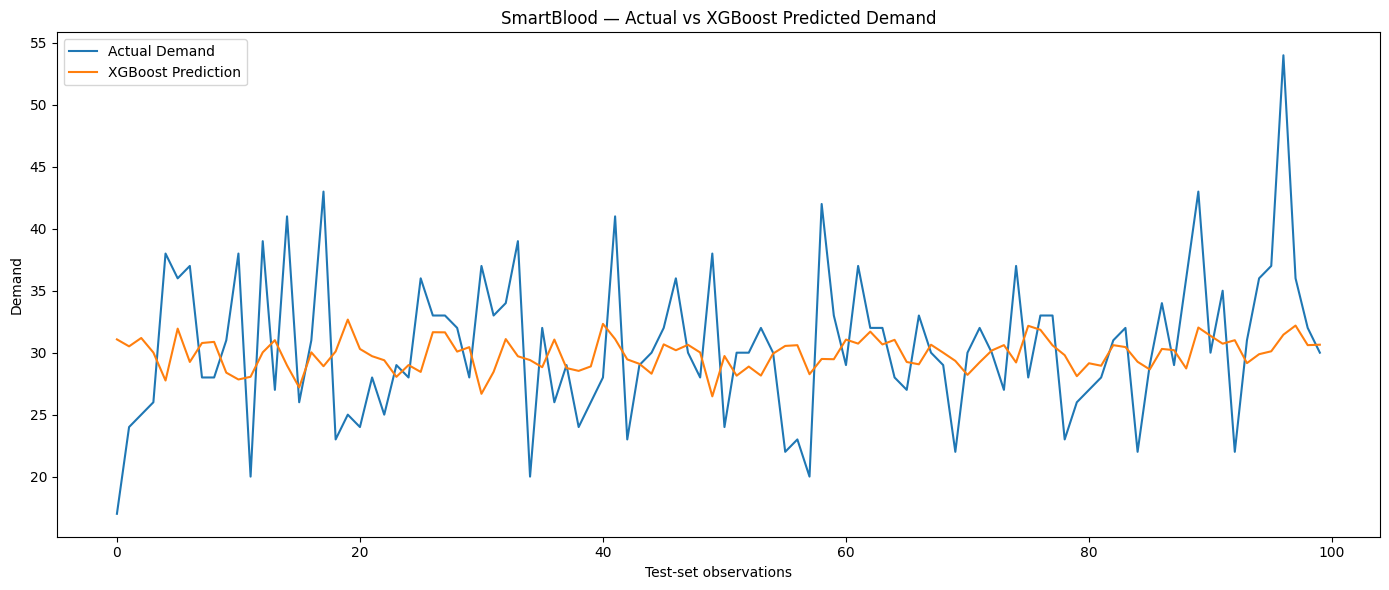

In [21]:
plot_data = predictions.head(100).copy()

plt.figure(figsize=(14, 6))
plt.plot(
    plot_data["target_demand"].values,
    label="Actual Demand"
)
plt.plot(
    plot_data["xgboost_prediction"].values,
    label="XGBoost Prediction"
)

plt.title("SmartBlood — Actual vs XGBoost Predicted Demand")
plt.xlabel("Test-set observations")
plt.ylabel("Demand")
plt.legend()
plt.tight_layout()
plt.show()


In [22]:
# Show Actual vs XGBoost Predicted Demand
actual_vs_predicted = predictions[
    [
        "date",
        "target_date",
        "blood_group",
        "component",
        "target_demand",
        "xgboost_prediction"
    ]
].head(100).copy()

actual_vs_predicted["xgboost_prediction"] = (
    actual_vs_predicted["xgboost_prediction"].round(2)
)

actual_vs_predicted["error"] = (
    actual_vs_predicted["target_demand"]
    - actual_vs_predicted["xgboost_prediction"]
).round(2)

actual_vs_predicted["absolute_error"] = (
    actual_vs_predicted["error"].abs()
).round(2)

actual_vs_predicted.head(10)

,date,target_date,blood_group,component,target_demand,xgboost_prediction,error,absolute_error
579,2024-09-01,2024-09-02,A+,Plasma,17.000,31.070,-14.070,14.070
580,2024-09-02,2024-09-03,A+,Plasma,24.000,30.510,-6.510,6.510
581,2024-09-03,2024-09-04,A+,Plasma,25.000,31.190,-6.190,6.190
582,2024-09-04,2024-09-05,A+,Plasma,26.000,30.010,-4.010,4.010
583,2024-09-05,2024-09-06,A+,Plasma,38.000,27.760,10.240,10.240
584,2024-09-06,2024-09-07,A+,Plasma,36.000,31.940,4.060,4.060
585,2024-09-07,2024-09-08,A+,Plasma,37.000,29.250,7.750,7.750
586,2024-09-08,2024-09-09,A+,Plasma,28.000,30.780,-2.780,2.780
587,2024-09-09,2024-09-10,A+,Plasma,28.000,30.870,-2.870,2.870
588,2024-09-10,2024-09-11,A+,Plasma,31.000,28.390,2.610,2.610


## 20. XGBoost feature importance

This helps explain which features the model used most strongly. It is useful for the explainable-ML part of SmartBlood.


In [23]:
feature_importance = pd.DataFrame({
    "Feature": feature_columns,
    "Importance": xgb_model_final.feature_importances_
}).sort_values(
    "Importance",
    ascending=False
)

feature_importance.head(15)


,Feature,Importance
7,demand_rolling_30,0.481
6,demand_rolling_14,0.324
16,blood_group_AB-,0.043
5,demand_rolling_7,0.038
23,component_RBC,0.013
15,blood_group_AB+,0.008
9,target_day_of_week_num,0.007
14,blood_group_A-,0.006
12,target_is_weekend,0.006
19,blood_group_O+,0.006


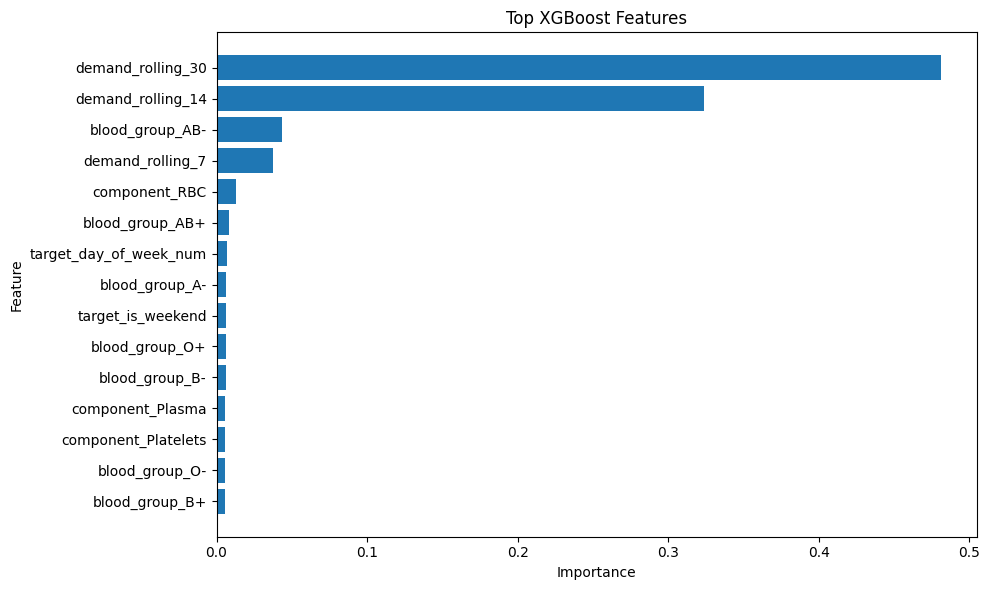

In [24]:
plt.figure(figsize=(10, 6))

top_features = feature_importance.head(15).sort_values(
    "Importance"
)

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.title("Top XGBoost Features")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()


## 21. Save the final XGBoost model

The saved model can later be loaded by the Python backend used by the SmartBlood dashboard.


In [25]:
MODEL_PATH = "../outputs/models/smartblood_xgboost_model.pkl"

joblib.dump(
    xgb_model_final,
    MODEL_PATH
)

print(f"XGBoost model saved to: {MODEL_PATH}")


XGBoost model saved to: ../outputs/models/smartblood_xgboost_model.pkl


## 22. Save the feature list

The backend must provide the same feature structure when making a prediction.


In [26]:
FEATURES_PATH = "../outputs/models/smartblood_xgboost_features.pkl"

joblib.dump(
    feature_columns,
    FEATURES_PATH
)

print(f"Feature list saved to: {FEATURES_PATH}")


Feature list saved to: ../outputs/models/smartblood_xgboost_features.pkl


# 23. Example: Make a prediction

For the actual dashboard, the backend will generate the same feature columns and call `model.predict()`.

The example below demonstrates the prediction call using an existing test observation.


In [27]:
sample_input = X_test.iloc[[0]]

prediction = xgb_model_final.predict(
    sample_input
)[0]

prediction = max(0, prediction)

print(f"Predicted next-day demand = {prediction:.0f} units")


Predicted next-day demand = 31 units


# Week 3 checkpoint

At this point SmartBlood has:

- Time-based train/validation/test forecasting
- Naive Forecast baseline
- 7-Day Moving Average baseline
- Random Forest
- XGBoost
- MAE, RMSE, and MAPE evaluation
- Actual vs predicted results
- XGBoost feature importance
- Saved XGBoost model
- Saved feature list
- Example `model.predict()` workflow

The next major step is to connect this forecasting output to the **inventory risk logic**:
**shortage risk + excess-stock risk + expiry risk**.
